# Background

- **Author**: 許以琳
- **Created At**: 2026-11-10
- **Research Motivation and Context (why are we interested in the findings?)：** 先前的 k-means（[candidate_kmeans_elbow.ipynb](candidate_kmeans_elbow.ipynb)）與 PAM（[candidate_pam_gower.ipynb](candidate_pam_gower.ipynb)）用 267 人（全部縣市長＋臺北、高雄議員）。依許以琳 2026-11-10 的決定，本 notebook 拿掉其他縣市的首長，**只用臺北市與高雄市的候選人**（北高首長＋北高議員），兩種方法用相同設定重跑：k-means（G1–G6 拆成 12 個 0/1 欄位、年齡縮放到 0–1）與 PAM（Gower 距離、六變數等權）。原本兩個 notebook 不修改。輸入：`data/processed/candidates_scope_g1_g6_20261108.csv`（產生方式見 [處理筆記本](../data/code/merge_scope_g1_g6_20261108.ipynb)），只取 `county_city` 為臺北市或高雄市者。
- **Main Findings and Takeaways：** 只用臺北、高雄 198 人（首長 11、議員 187）重跑：(1) k-means 的 elbow 切點仍是 k = 4，四群為國民黨（54）、大學學歷跨黨（52）、民進黨（49）、無黨籍／小黨（43），和 267 人版本幾乎相同（ARI 0.987），穩定（抽樣重跑平均 ARI 0.916、排除約略年齡後 0.879），但仍主要反映政黨。(2) PAM 的切點變成 k = 5（k = 3–5 離連線距離 11.20、11.76、12.23 很接近）：男性民進黨為主（52）、大學學歷（40）、政治家族（36，有親屬 89%）、首次參選（35，94%）、女性民進黨為主（35）；k = 4 為女性（59）、年長男性（55）、大學學歷民進黨為主（50）、首次參選（34）。PAM 仍不穩定（平均 ARI 0.379–0.424，排除約略年齡後 0.128–0.197），和 267 人版本的 ARI 為 0.395（k = 4）。(3) 拿掉其他縣市首長不會改變主要結論：k-means 穩定但等於政黨，PAM 有意義但不穩。
- **Future Direction：** 與 267 人版本、張睿庠的 G5 × G6 分組比較；G6 與組員資料有 32 人不一致，核對後需重跑。
<!-- Deliver the ipynb in finding/ directly for review, retaining actual outputs.
HTML is not required and is produced only when separately requested. Use the
student's requested or existing filename, or a descriptive basename. Created At
is the fixed creation date. Follow the project-root FINDING-RULES.md for handoff
and external-action scope. -->


In [1]:
# Load packages here
from pathlib import Path
import hashlib
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
# 本機 Windows 的應用程式控制原則封鎖 scikit-learn 的編譯元件，k-means、PAM、輪廓係數與 ARI 以 numpy 實作（與先前 notebook 相同）。


In [2]:
# Load input data here and please finish all the data manipulation here.
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "templates").is_dir():
            return candidate
    raise FileNotFoundError("請在含 AGENTS.md 與 templates/ 的專案內開啟本 notebook。")

PROJECT_ROOT = find_project_root()
DATA_REL = "data/processed/candidates_scope_g1_g6_20261108.csv"
EXPECTED_SHA256 = "5af31805a707502198004aad222ac9a61c4309d9bc27cfa1c059450d74b8e6a6"
data_path = PROJECT_ROOT / DATA_REL
assert data_path.is_file(), f"找不到輸入檔：{DATA_REL}"
actual = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert actual == EXPECTED_SHA256, f"輸入檔內容已變動（{actual}），請先確認新版本再分析。"

raw = pd.read_csv(data_path, dtype=str, encoding="utf-8-sig")
need = ["candidate_key", "candidate_name", "office_type", "county_city", "G1_age_2026_minus_birth_year",
        "G1_age_basis", "G2_sex", "G3_education_level", "G4_party",
        "G5_first_time_any_elected_office", "G6_political_family"]
assert set(need) <= set(raw.columns) and raw["candidate_key"].is_unique

def prep(frame):
    d = frame[need].copy().reset_index(drop=True)
    d["age"] = pd.to_numeric(d["G1_age_2026_minus_birth_year"], errors="raise")
    d["sex"] = d["G2_sex"]
    d["education"] = d["G3_education_level"]
    d["party"] = d["G4_party"]
    d["first_time"] = d["G5_first_time_any_elected_office"].map({"1": "首次參選", "0": "曾參選"})
    d["political_family"] = d["G6_political_family"].map({"1": "有", "0": "無"})
    return d

full = prep(raw)                                            # 267 人版本（對照用）
df = prep(raw[raw["county_city"].isin(["臺北市", "高雄市"])])  # 本分析：只留臺北、高雄
analysis_vars = ["age", "sex", "education", "party", "first_time", "political_family"]
assert df[analysis_vars].notna().all().all()
print("分析樣本（臺北＋高雄）：", len(df), "人；排除其他縣市首長", len(full) - len(df), "人")
print(pd.crosstab(df["county_city"], df["office_type"], margins=True, margins_name="合計"))
df[["candidate_name", "office_type", "county_city"] + analysis_vars].head(10)


分析樣本（臺北＋高雄）： 198 人；排除其他縣市首長 69 人
office_type  直轄市議員  直轄市長   合計
county_city                  
臺北市             90     6   96
高雄市             97     5  102
合計             187    11  198


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
0,郭璽,直轄市長,臺北市,68,男,大學,其他政黨,曾參選,無
1,沈伯洋,直轄市長,臺北市,44,男,研究所,民進黨,曾參選,無
2,蕭文乾,直轄市長,臺北市,52,男,研究所,其他政黨,曾參選,無
3,唐新民,直轄市長,臺北市,76,男,研究所,其他政黨,曾參選,無
4,蔣萬安,直轄市長,臺北市,48,男,研究所,國民黨,曾參選,有
5,林志成,直轄市長,臺北市,61,男,研究所,無黨籍／未經政黨推薦,曾參選,無
6,張靜,直轄市長,高雄市,70,男,大學,其他政黨,曾參選,無
7,賴瑞隆,直轄市長,高雄市,53,男,研究所,民進黨,曾參選,無
8,王肇民,直轄市長,高雄市,63,男,大學,無黨籍／未經政黨推薦,首次參選,無
9,柯志恩,直轄市長,高雄市,64,女,研究所,國民黨,曾參選,有


In [3]:
# Before conducting the analysis, report summary statistics for all variables used.
LABELS = {"age": "G1 年齡（2026 − 出生年）", "sex": "G2 性別", "education": "G3 最高已完成學歷",
          "party": "G4 政黨（登記推薦）", "first_time": "G5 是否首次參選任何民選公職",
          "political_family": "G6 政治家族（配偶或三親等內親屬任公職）"}
N = len(df)
d = df["age"].describe(percentiles=[.25, .5, .75])
print(f"表 1　數值變數摘要統計（N = {N}）")
display(pd.DataFrame({"平均": [d["mean"]], "最小值": [d["min"]], "第25百分位": [d["25%"]], "中位數": [d["50%"]],
                      "第75百分位": [d["75%"]], "最大值": [d["max"]], "標準差": [d["std"]], "有效 N": [int(d["count"])],
                      "缺值 N": [int(df["age"].isna().sum())]}, index=[LABELS["age"]]).round(2))
rows = []
for v in ["sex", "education", "party", "first_time", "political_family"]:
    vc = df[v].value_counts(); nn = int(df[v].notna().sum())
    for cat, cnt in vc.head(10).items():
        rows.append({"變數": LABELS[v], "類別": cat, "人數": int(cnt), "百分比（%）": round(100 * cnt / nn, 1),
                     "有效 N": nn, "缺值 N": int(df[v].isna().sum())})
print(f"表 2　類別變數摘要統計（N = {N}；百分比分母為該變數非缺值人數）")
display(pd.DataFrame(rows).set_index(["變數", "類別"]))


表 1　數值變數摘要統計（N = 198）


,平均,最小值,第25百分位,中位數,第75百分位,最大值,標準差,有效 N,缺值 N
G1 年齡（2026 − 出生年）,50.32,24.0,42.0,49.0,58.75,83.0,11.77,198,0


表 2　類別變數摘要統計（N = 198；百分比分母為該變數非缺值人數）


人數  百分比（%）  有效 N  缺值 N
變數                    類別                                 
G2 性別                 男           118    59.6   198     0
                      女            80    40.4   198     0
G3 最高已完成學歷            研究所         127    64.1   198     0
                      大學           52    26.3   198     0
                      大學以下         19     9.6   198     0
G4 政黨（登記推薦）           國民黨          68    34.3   198     0
                      民進黨          63    31.8   198     0
                      無黨籍／未經政黨推薦   39    19.7   198     0
                      其他政黨         21    10.6   198     0
                      民眾黨           7     3.5   198     0
G5 是否首次參選任何民選公職       曾參選         158    79.8   198     0
                      首次參選         40    20.2   198     0
G6 政治家族（配偶或三親等內親屬任公職） 無           160    80.8   198     0
                      有            38    19.2   198     0

### The actual analysis starts below

**設定與先前相同，只換樣本。**

- **k-means**：G1 年齡以本樣本的最小、最大值縮放到 0–1；G2 女性＝1；G3 學歷拆 3 欄、G4 政黨拆 5 欄（0/1）；G5、G6 為 0/1，共 12 欄。每個 k 試 50 組 k-means++ 起點，取群內平方和（WCSS）最小的解。
- **PAM**：Gower 距離，年齡差距 ÷ 本樣本年齡全距，其餘五個類別變數相同 0、不同 1，六項平均；BUILD＋SWAP 求代表人物（medoid）。

**選 k。** 兩種方法都跑 k = 1–10，以平移首尾連線找 elbow 切點，並看平均輪廓係數與最小群人數。最終分群採各自的 elbow 切點；若切點不是 4，另列 k = 4 的結果以便和 267 人版本比較。

**穩定度與比較。** 抽 80% 重跑 50 次、排除年齡來自報導或約略值者重跑；並和 267 人版本在這 198 人上的分群比較（ARI）。


In [4]:
PARTIES = ["國民黨", "民進黨", "民眾黨", "其他政黨", "無黨籍／未經政黨推薦"]

def feat(frame):
    amin, amax = frame["age"].min(), frame["age"].max()
    X = pd.DataFrame(index=frame.index)
    X["age"] = (frame["age"] - amin) / (amax - amin)
    X["female"] = (frame["sex"] == "女").astype(int)
    for lvl in ["大學以下", "大學", "研究所"]:
        X[lvl] = (frame["education"] == lvl).astype(int)
    for p in PARTIES:
        X[p] = (frame["party"] == p).astype(int)
    X["first"] = (frame["first_time"] == "首次參選").astype(int)
    X["family"] = (frame["political_family"] == "有").astype(int)
    return X.values.astype(float)

def gower(frame, age_range=None):
    a = frame["age"].to_numpy(float)
    r = (a.max() - a.min()) if age_range is None else age_range
    Dm = np.abs(a[:, None] - a[None, :]) / r
    for v in ["sex", "education", "party", "first_time", "political_family"]:
        x = frame[v].to_numpy()
        Dm = Dm + (x[:, None] != x[None, :])
    return Dm / 6

def kmeans(X, k, n_init=50, max_iter=300, tol=1e-8, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        Cc = [X[rng.integers(len(X))]]
        for _ in range(1, k):
            d2 = np.min(((X[:, None, :] - np.array(Cc)[None]) ** 2).sum(-1), axis=1)
            Cc.append(X[rng.choice(len(X), p=d2 / d2.sum())] if d2.sum() > 0 else X[rng.integers(len(X))])
        Cc = np.array(Cc, dtype=float)
        for _ in range(max_iter):
            lab = ((X[:, None, :] - Cc[None]) ** 2).sum(-1).argmin(1)
            newC = np.array([X[lab == j].mean(0) if (lab == j).any() else Cc[j] for j in range(k)])
            shift = ((newC - Cc) ** 2).sum()
            Cc = newC
            if shift <= tol:
                break
        lab = ((X[:, None, :] - Cc[None]) ** 2).sum(-1).argmin(1)
        inertia = ((X - Cc[lab]) ** 2).sum()
        if best is None or inertia < best[1] - 1e-12:
            best = (lab, inertia)
    return best

def pam(Dm, k, max_iter=200):
    n = len(Dm)
    med = [int(Dm.sum(1).argmin())]
    while len(med) < k:
        dmin = Dm[:, med].min(1)
        gain = np.maximum(dmin[None, :] - Dm, 0).sum(1)
        gain[med] = -1
        med.append(int(gain.argmax()))
    med = np.array(med)
    for _ in range(max_iter):
        dm = Dm[:, med]
        order = np.argsort(dm, axis=1)
        near = order[:, 0]
        d1 = dm[np.arange(n), near]
        d2 = dm[np.arange(n), order[:, 1]] if k > 1 else np.full(n, np.inf)
        cost = d1.sum()
        best = (0.0, None, None)
        nonmed = np.setdiff1d(np.arange(n), med)
        for i in range(k):
            base = np.where(near == i, d2, d1)
            newc = np.minimum(Dm[nonmed, :], base[None, :]).sum(1) - cost
            j = newc.argmin()
            if newc[j] < best[0] - 1e-12:
                best = (newc[j], i, nonmed[j])
        if best[1] is None:
            break
        med[best[1]] = best[2]
    lab = Dm[:, med].argmin(1)
    return lab, Dm[np.arange(n), med[lab]].sum(), med

def silhouette_D(Dm, lab):
    s = np.zeros(len(Dm))
    for i in range(len(Dm)):
        same = lab == lab[i]
        if same.sum() <= 1:
            continue
        a = Dm[i, same].sum() / (same.sum() - 1)
        b = min(Dm[i, lab == c].mean() for c in np.unique(lab) if c != lab[i])
        s[i] = 0 if max(a, b) == 0 else (b - a) / max(a, b)
    return s.mean()

def eucl(X):
    return np.sqrt(((X[:, None, :] - X[None]) ** 2).sum(-1))

def ari(a, b):
    ct = pd.crosstab(pd.Series(list(a)), pd.Series(list(b))).values
    sij = sum(comb(int(n), 2) for n in ct.ravel())
    sa = sum(comb(int(n), 2) for n in ct.sum(1)); sb = sum(comb(int(n), 2) for n in ct.sum(0))
    tot = comb(int(ct.sum()), 2); e = sa * sb / tot
    return (sij - e) / ((sa + sb) / 2 - e)

def tangent(series):
    ks = np.array(series.index, float)
    chord = series.iloc[0] + (series.iloc[-1] - series.iloc[0]) / (ks[-1] - ks[0]) * (ks - ks[0])
    gap = pd.Series(chord - series.values, index=series.index)
    return int(gap.idxmax()), gap

def relabel(lab):
    order = pd.Series(lab).value_counts().index.tolist()
    return pd.Series(lab).map({o: i + 1 for i, o in enumerate(order)}).values

X = feat(df); D = gower(df); Eu = eucl(X)
print(f"k-means 特徵矩陣 {X.shape}；Gower 距離 {D.shape}，兩兩平均 {D[np.triu_indices(len(D), 1)].mean():.3f}")

rows = []
for k in range(1, 11):
    lk, wk = kmeans(X, k, n_init=50, seed=20261110 + k)
    lp, cp, _ = pam(D, k)
    rows.append({"k": k, "k-means WCSS": wk, "k-means 輪廓係數": silhouette_D(Eu, lk) if k > 1 else np.nan,
                 "k-means 最小群": int(np.bincount(lk, minlength=k).min()),
                 "PAM 總成本": cp, "PAM 輪廓係數": silhouette_D(D, lp) if k > 1 else np.nan,
                 "PAM 最小群": int(np.bincount(lp, minlength=k).min())})
ch = pd.DataFrame(rows).set_index("k")
ch.insert(1, "k-means 減少（%）", 100 * (-ch["k-means WCSS"].diff()) / ch["k-means WCSS"].shift())
ch.insert(5, "PAM 減少（%）", 100 * (-ch["PAM 總成本"].diff()) / ch["PAM 總成本"].shift())
K_KM, gap_km = tangent(ch["k-means WCSS"])
K_PAM, gap_pam = tangent(ch["PAM 總成本"])
print(f"表 3　臺北＋高雄：k = 1–10 的 WCSS／總成本、輪廓係數與最小群（N = {len(df)}）")
display(ch.round(3))
print(f"平移首尾連線切點：k-means k = {K_KM}（離連線 {gap_km.max():.2f}）；PAM k = {K_PAM}（離連線 {gap_pam.max():.2f}）")
print("k-means 各 k 離連線距離：", gap_km.round(2).to_dict())
print("PAM 各 k 離連線距離：", gap_pam.round(2).to_dict())


k-means 特徵矩陣 (198, 12)；Gower 距離 (198, 198)，兩兩平均 0.432


表 3　臺北＋高雄：k = 1–10 的 WCSS／總成本、輪廓係數與最小群（N = 198）


,k-means WCSS,k-means 減少（%）,k-means 輪廓係數,k-means 最小群,PAM 總成本,PAM 減少（%）,PAM 輪廓係數,PAM 最小群
k,,,,,,,,
1,363.653,NaN,NaN,198,65.268,NaN,NaN,198
2,287.438,20.958,0.241,71,51.345,21.333,0.233,84
3,240.696,16.262,0.236,54,44.969,12.417,0.220,61
4,204.377,15.089,0.288,43,39.850,11.383,0.226,34
5,182.022,10.938,0.309,19,34.831,12.597,0.242,35
6,168.690,7.324,0.322,14,32.407,6.959,0.227,29
7,155.179,8.010,0.309,19,29.559,8.787,0.249,23
8,143.175,7.736,0.319,17,27.415,7.253,0.263,18
9,136.506,4.658,0.344,9,25.757,6.048,0.295,17


平移首尾連線切點：k-means k = 4（離連線 78.90）；PAM k = 5（離連線 12.23）
k-means 各 k 離連線距離： {1: 0.0, 2: 49.42, 3: 69.37, 4: 78.9, 5: 74.46, 6: 61.0, 7: 47.72, 8: 32.94, 9: 12.81, 10: 0.0}
PAM 各 k 離連線距離： {1: 0.0, 2: 9.37, 3: 11.2, 4: 11.76, 5: 12.23, 6: 10.11, 7: 8.4, 8: 5.99, 9: 3.1, 10: 0.0}


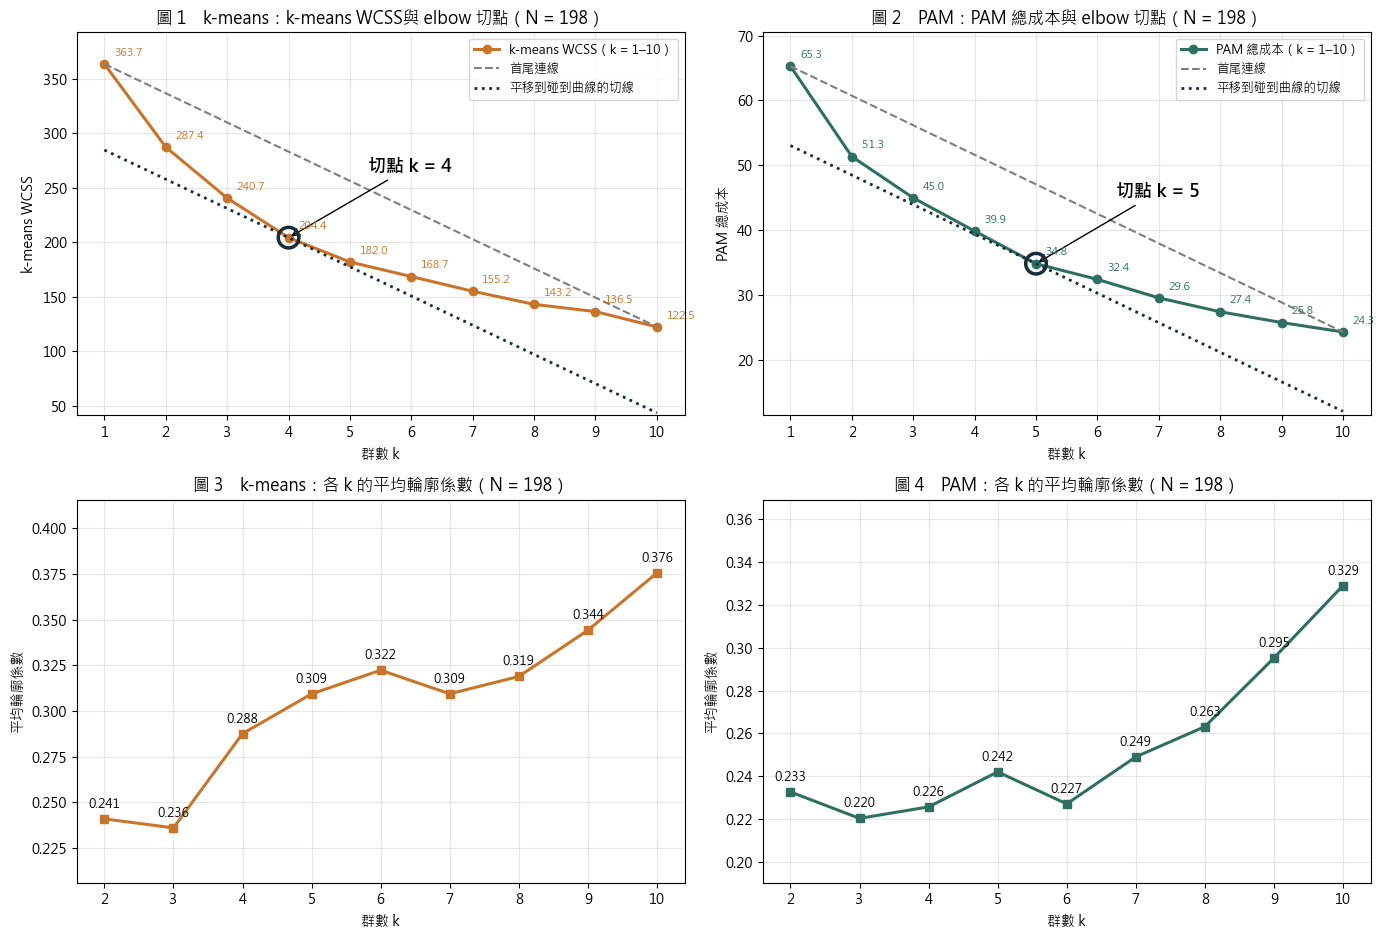

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
for col_i, (col, sil, kk, gap, color, name) in enumerate([
        ("k-means WCSS", "k-means 輪廓係數", K_KM, gap_km, "#C8742B", "k-means"),
        ("PAM 總成本", "PAM 輪廓係數", K_PAM, gap_pam, "#2f6f62", "PAM")]):
    ax = axes[0, col_i]
    w = ch[col]; ks = np.array(w.index, float)
    chord = w.iloc[0] + (w.iloc[-1] - w.iloc[0]) / 9 * (ks - 1)
    ax.plot(ks, w.values, marker="o", color=color, linewidth=2.2, label=f"{col}（k = 1–10）")
    ax.plot([1, 10], [w.iloc[0], w.iloc[-1]], linestyle="--", color="#7f7f7f", label="首尾連線")
    ax.plot(ks, chord - gap.max(), linestyle=":", color="#182D39", linewidth=2, label="平移到碰到曲線的切線")
    ax.scatter([kk], [w.loc[kk]], s=220, facecolors="none", edgecolors="#182D39", linewidths=2.5, zorder=4)
    ax.annotate(f"切點 k = {kk}", xy=(kk, w.loc[kk]), xytext=(kk + 1.3, w.loc[kk] + (w.max() - w.min()) * 0.25),
                fontsize=13, fontweight="bold", arrowprops=dict(arrowstyle="->"))
    for k, v in w.items():
        ax.annotate(f"{v:.1f}", (k, v), textcoords="offset points", xytext=(7, 6), fontsize=8, color=color)
    ax.set_title(f"圖 {1 + col_i}　{name}：{col}與 elbow 切點（N = {len(df)}）")
    ax.set_xlabel("群數 k"); ax.set_ylabel(col); ax.set_xticks(ks)
    ax.set_ylim(min((chord - gap.max()).min(), w.min()) * 0.95, w.max() * 1.08)
    ax.legend(loc="upper right", fontsize=9); ax.grid(alpha=.3)
    ax = axes[1, col_i]
    s = ch[sil].dropna()
    ax.plot(s.index, s.values, marker="s", color=color, linewidth=2.2)
    for k, v in s.items():
        ax.annotate(f"{v:.3f}", (k, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    ax.set_title(f"圖 {3 + col_i}　{name}：各 k 的平均輪廓係數（N = {len(df)}）")
    ax.set_xlabel("群數 k"); ax.set_ylabel("平均輪廓係數"); ax.set_xticks(s.index)
    ax.set_ylim(s.min() - 0.03, s.max() + 0.04); ax.grid(alpha=.3)
fig.tight_layout()
asset_dir = PROJECT_ROOT / "finding" / "candidate_cluster_taipei_kaohsiung_assets"
asset_dir.mkdir(exist_ok=True)
fig.savefig(asset_dir / "tk_choose_k.png", dpi=200)
plt.show()


In [6]:
def describe(g):
    col = {"人數": len(g), "平均年齡": g["age"].mean(), "女性（%）": 100 * (g["sex"] == "女").mean()}
    for lvl in ["研究所", "大學", "大學以下"]:
        col[f"學歷：{lvl}（%）"] = 100 * (g["education"] == lvl).mean()
    for pty in PARTIES:
        col[f"政黨：{pty}（%）"] = 100 * (g["party"] == pty).mean()
    col["首次參選（%）"] = 100 * (g["first_time"] == "首次參選").mean()
    col["政治家族（%）"] = 100 * (g["political_family"] == "有").mean()
    col["首長（%）"] = 100 * (g["office_type"] == "直轄市長").mean()
    col["高雄（%）"] = 100 * (g["county_city"] == "高雄市").mean()
    return col

results = {}
versions = [("k-means", K_KM), ("PAM", K_PAM)]
if K_KM != 4:
    versions.append(("k-means", 4))
if K_PAM != 4:
    versions.append(("PAM", 4))
for method, k in versions:
    if method == "k-means":
        lab = relabel(kmeans(X, k, n_init=50, seed=20261110 + k)[0]); med = None
    else:
        l, _, med = pam(D, k); lab = relabel(l)
    name = f"{method} k = {k}"
    results[name] = {"lab": lab, "k": k, "method": method, "med": med, "raw": None if med is None else l}
    df["_c"] = lab
    prof = pd.DataFrame({f"第 {c} 群": describe(g) for c, g in df.groupby("_c")})
    prof["全樣本"] = pd.Series(describe(df))
    results[name]["profile"] = prof
    print(f"表　{name}（臺北＋高雄，N = {len(df)}）各群特徵；百分比分母為該群人數")
    display(prof.round(1))
    if med is not None:
        rel = {o: i + 1 for i, o in enumerate(pd.Series(l).value_counts().index.tolist())}
        mt = df.iloc[med][["candidate_name", "office_type", "county_city", "age", "sex", "education", "party", "first_time", "political_family"]].copy()
        mt.insert(0, "群別", [f"第 {rel[i]} 群" for i in range(k)])
        print(f"　{name} 各群代表人物（medoid）")
        display(mt.sort_values("群別").set_index("群別"))
df = df.drop(columns="_c")


表　k-means k = 4（臺北＋高雄，N = 198）各群特徵；百分比分母為該群人數


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,54.0,52.0,49.0,43.0,198.0
平均年齡,53.1,47.0,48.9,52.5,50.3
女性（%）,46.3,40.4,40.8,32.6,40.4
學歷：研究所（%）,88.9,0.0,98.0,72.1,64.1
學歷：大學（%）,0.0,100.0,0.0,0.0,26.3
學歷：大學以下（%）,11.1,0.0,2.0,27.9,9.6
政黨：國民黨（%）,100.0,26.9,0.0,0.0,34.3
政黨：民進黨（%）,0.0,26.9,100.0,0.0,31.8
政黨：民眾黨（%）,0.0,9.6,0.0,4.7,3.5
政黨：其他政黨（%）,0.0,17.3,0.0,27.9,10.6


表　PAM k = 5（臺北＋高雄，N = 198）各群特徵；百分比分母為該群人數


,第 1 群,第 2 群,第 3 群,第 4 群,第 5 群,全樣本
人數,52.0,40.0,36.0,35.0,35.0,198.0
平均年齡,55.4,49.6,46.0,44.5,53.8,50.3
女性（%）,0.0,25.0,75.0,22.9,100.0,40.4
學歷：研究所（%）,82.7,10.0,75.0,65.7,85.7,64.1
學歷：大學（%）,5.8,77.5,16.7,22.9,11.4,26.3
學歷：大學以下（%）,11.5,12.5,8.3,11.4,2.9,9.6
政黨：國民黨（%）,15.4,50.0,69.4,14.3,28.6,34.3
政黨：民進黨（%）,51.9,7.5,19.4,20.0,54.3,31.8
政黨：民眾黨（%）,1.9,7.5,2.8,2.9,2.9,3.5
政黨：其他政黨（%）,11.5,17.5,2.8,14.3,5.7,10.6


　PAM k = 5 各群代表人物（medoid）


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
群別,,,,,,,,,
第 1 群,張勝富,直轄市議員,高雄市,54,男,研究所,民進黨,曾參選,無
第 2 群,宋立彬,直轄市議員,高雄市,48,男,大學,國民黨,曾參選,無
第 3 群,邱于軒,直轄市議員,高雄市,44,女,研究所,國民黨,曾參選,有
第 4 群,陳彥廷,直轄市議員,臺北市,43,男,研究所,無黨籍／未經政黨推薦,首次參選,無
第 5 群,許淑華,直轄市議員,臺北市,53,女,研究所,民進黨,曾參選,無


表　PAM k = 4（臺北＋高雄，N = 198）各群特徵；百分比分母為該群人數


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,59.0,55.0,50.0,34.0,198.0
平均年齡,51.0,57.1,46.3,44.1,50.3
女性（%）,100.0,0.0,24.0,26.5,40.4
學歷：研究所（%）,79.7,80.0,24.0,70.6,64.1
學歷：大學（%）,13.6,3.6,72.0,17.6,26.3
學歷：大學以下（%）,6.8,16.4,4.0,11.8,9.6
政黨：國民黨（%）,54.2,50.9,10.0,8.8,34.3
政黨：民進黨（%）,32.2,18.2,54.0,20.6,31.8
政黨：民眾黨（%）,1.7,1.8,8.0,2.9,3.5
政黨：其他政黨（%）,3.4,12.7,14.0,14.7,10.6


　PAM k = 4 各群代表人物（medoid）


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
群別,,,,,,,,,
第 1 群,李雅靜,直轄市議員,高雄市,49,女,研究所,國民黨,曾參選,無
第 2 群,吳利成,直轄市議員,高雄市,57,男,研究所,國民黨,曾參選,無
第 3 群,何權峰,直轄市議員,高雄市,46,男,大學,民進黨,曾參選,無
第 4 群,陳彥廷,直轄市議員,臺北市,43,男,研究所,無黨籍／未經政黨推薦,首次參選,無


表　穩定度（臺北＋高雄 N = 198；抽 80%＝158 人重跑 50 次；排除報導／約略年齡者 N = 176）


,抽 80% 重跑平均 ARI,最低 ARI,ARI ≥ 0.9（%）,排除約略年齡後 ARI,輪廓係數
版本,,,,,
k-means k = 4,0.916,0.576,64.0,0.879,0.288
PAM k = 5,0.424,0.163,4.0,0.197,0.242
PAM k = 4,0.379,0.112,16.0,0.128,0.226


表　與 267 人版本、與政黨的一致程度（N = 198）；本樣本 k-means 與 PAM（各自切點）之間 ARI = 0.177


,與 267 人版（同方法 k = 4）的 ARI,與政黨本身的 ARI
版本,,
PAM k = 4,0.395,0.113
PAM k = 5,0.204,0.099
k-means k = 4,0.987,0.553


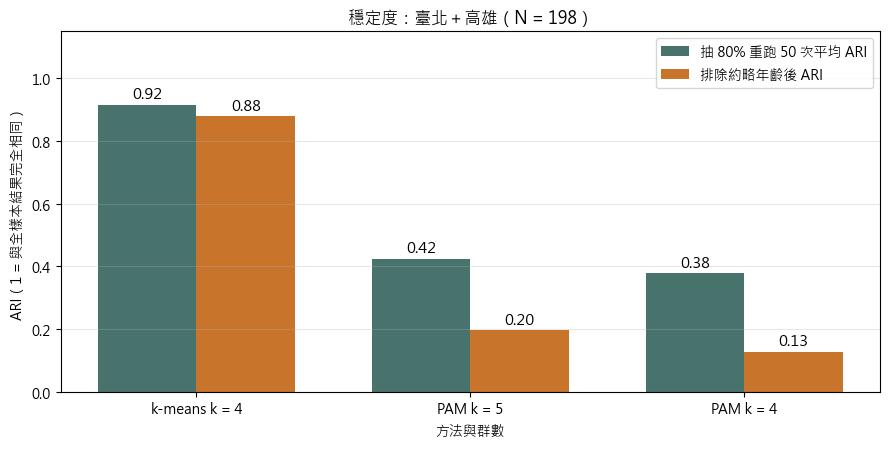

In [7]:
# 穩定度：抽 80% 重跑 50 次（兩方法同一批抽樣）、排除報導／約略年齡者重跑
rng = np.random.default_rng(20261110)
n = len(df); m = int(round(0.8 * n))
age_range = df["age"].max() - df["age"].min()
keep = np.where(df["G1_age_basis"].isin(["birth_date", "existing_source"]).to_numpy())[0]
srows = []
for name, r in results.items():
    k = r["k"]; boot = []
    rng = np.random.default_rng(20261110)
    for rep in range(50):
        idx = np.sort(rng.choice(n, m, replace=False))
        if r["method"] == "k-means":
            l = kmeans(X[idx], k, n_init=10, seed=20261110 + 100 + rep)[0]
        else:
            l = pam(D[np.ix_(idx, idx)], k)[0]
        boot.append(ari(r["lab"][idx], l))
    boot = np.array(boot)
    if r["method"] == "k-means":
        le = kmeans(X[keep], k, n_init=50, seed=20261110 + k)[0]
    else:
        le = pam(D[np.ix_(keep, keep)], k)[0]
    srows.append({"版本": name, "抽 80% 重跑平均 ARI": boot.mean(), "最低 ARI": boot.min(),
                  "ARI ≥ 0.9（%）": 100 * (boot >= 0.9).mean(), "排除約略年齡後 ARI": ari(r["lab"][keep], le),
                  "輪廓係數": silhouette_D(Eu if r["method"] == "k-means" else D, r["lab"])})
stab_tbl = pd.DataFrame(srows).set_index("版本")
print(f"表　穩定度（臺北＋高雄 N = {n}；抽 80%＝{m} 人重跑 50 次；排除報導／約略年齡者 N = {len(keep)}）")
display(stab_tbl.round(3))

# 和 267 人版本比較（在這 198 人上）
Xf = feat(full); Df = gower(full)
lab267_km = relabel(kmeans(Xf, 4, n_init=50, seed=20261110 + 4)[0])
lab267_pam = relabel(pam(Df, 4)[0])
assert sorted(pd.Series(lab267_km).value_counts().tolist()) == [64, 65, 68, 70]
assert sorted(pd.Series(lab267_pam).value_counts().tolist()) == [51, 66, 74, 76]
pos = full.index[full["candidate_key"].isin(df["candidate_key"])].to_numpy()
key_order = full.loc[pos, "candidate_key"].to_numpy()
assert (key_order == df["candidate_key"].to_numpy()).all()
crows = []
for name, r in results.items():
    ref = lab267_km if r["method"] == "k-means" else lab267_pam
    crows.append({"版本": name, "與 267 人版（同方法 k = 4）的 ARI": ari(r["lab"], ref[pos])})
for name, r in results.items():
    crows.append({"版本": name, "與政黨本身的 ARI": ari(r["lab"], df["party"])})
cmp_tbl = pd.DataFrame(crows).groupby("版本").first()
km_main = f"k-means k = {K_KM}"; pam_main = f"PAM k = {K_PAM}"
print(f"表　與 267 人版本、與政黨的一致程度（N = {n}）；本樣本 k-means 與 PAM（各自切點）之間 ARI = "
      f"{ari(results[km_main]['lab'], results[pam_main]['lab']):.3f}")
display(cmp_tbl.round(3))

fig, ax = plt.subplots(figsize=(9, 4.6))
names = list(stab_tbl.index)
vals = stab_tbl["抽 80% 重跑平均 ARI"].values
ex = stab_tbl["排除約略年齡後 ARI"].values
x = np.arange(len(names))
ax.bar(x - 0.18, vals, width=0.36, color="#47736C", label="抽 80% 重跑 50 次平均 ARI")
ax.bar(x + 0.18, ex, width=0.36, color="#C8742B", label="排除約略年齡後 ARI")
for xi, v in zip(x - 0.18, vals):
    ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)
for xi, v in zip(x + 0.18, ex):
    ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylim(0, 1.15); ax.set_ylabel("ARI（1 = 與全樣本結果完全相同）"); ax.set_xlabel("方法與群數")
ax.set_title(f"穩定度：臺北＋高雄（N = {n}）")
ax.legend(loc="upper right", fontsize=10); ax.grid(alpha=.3, axis="y")
fig.tight_layout()
fig.savefig(asset_dir / "tk_stability.png", dpi=200)
plt.show()


In [8]:
out = df[["candidate_key", "candidate_name", "office_type", "county_city"]].copy()
for name, r in results.items():
    out[name.replace(" ", "")] = r["lab"]
out_path = asset_dir / "cluster_labels_taipei_kaohsiung.csv"
out.to_csv(out_path, index=False, encoding="utf-8-sig")
chk = pd.read_csv(out_path, dtype=str, encoding="utf-8-sig")
assert len(chk) == len(df) and chk["candidate_key"].is_unique
print("已存：", out_path.relative_to(PROJECT_ROOT).as_posix(), "；", len(chk), "列；欄位", list(chk.columns),
      "；SHA-256 =", hashlib.sha256(out_path.read_bytes()).hexdigest())


已存： finding/candidate_cluster_taipei_kaohsiung_assets/cluster_labels_taipei_kaohsiung.csv ； 198 列；欄位 ['candidate_key', 'candidate_name', 'office_type', 'county_city', 'k-meansk=4', 'PAMk=5', 'PAMk=4'] ；SHA-256 = 53671e2ba37f9b67e8338a5f184d7dfee030e6260a7b6190cc7237f8ddcbe536


### 結果說明

**樣本。** 臺北 96 人（首長 6、議員 90）、高雄 102 人（首長 5、議員 97），共 198 人；拿掉其他縣市首長 69 人。平均年齡 50.3 歲、女性 40.4%、研究所 64.1%、國民黨 34.3%、民進黨 31.8%、首次參選 20.2%、政治家族 19.2%。首長只有 11 人，結果主要反映議員。

**選 k（表 3、圖 1–4）。**

- k-means：WCSS 每多一群減少 21.0%、16.3%、15.1%、10.9%，之後多在 8% 以下；平移首尾連線切點 **k = 4**（離連線 78.9），和 267 人版本相同。
- PAM：總成本切點 **k = 5**（離連線 12.23），但 k = 3、4、5 的距離（11.20、11.76、12.23）很接近，手肘不明顯；267 人版本切點為 4。
- 兩者的輪廓係數都偏低（k-means k = 4 為 0.288；PAM k = 4、5 為 0.226、0.242），且隨 k 上升，不作為選 k 的主要依據。

**k-means k = 4。** 54／52／49／43 人：第 1 群全為國民黨（研究所 89%、政治家族 35%）；第 2 群全為大學學歷、政黨混合；第 3 群全為民進黨（研究所 98%）；第 4 群為無黨籍 67%＋其他政黨 28%（首次參選 35%、大學以下 28%）。和 267 人版本在這 198 人上的 ARI 為 0.987，幾乎相同；和政黨本身的 ARI 為 0.553。

**PAM k = 5（切點）。** 52／40／36／35／35 人：第 1 群全為男性、民進黨 52%、平均 55.4 歲；第 2 群大學學歷 78%、國民黨 50%；第 3 群政治家族 89%、女性 75%、國民黨 69%；第 4 群首次參選 94%、無黨籍 49%、平均 44.5 歲；第 5 群全為女性、民進黨 54%。和 k = 4 相比，多分出一個「政治家族」群。

**PAM k = 4（與 267 人版比較用）。** 59／55／50／34 人：女性（100%）、男性年長（57.1 歲，國民黨 51%）、大學學歷（72%，民進黨 54%）、首次參選（91%，無黨籍 53%）。和 267 人版本的 PAM（女性／民進黨年輕男性／國民黨年長男性／無黨籍素人）方向相近，但 ARI 只有 0.395。

**穩定度。**

| 版本 | 抽 80% 重跑平均 ARI | ARI ≥ 0.9 的比例 | 排除約略年齡後 ARI | 與 267 人版 ARI |
| --- | --- | --- | --- | --- |
| k-means k = 4 | 0.916 | 64% | 0.879 | 0.987 |
| PAM k = 5 | 0.424 | 4% | 0.197 | 0.204 |
| PAM k = 4 | 0.379 | 16% | 0.128 | 0.395 |

本樣本 k-means 與 PAM（各自切點）之間的 ARI 為 0.177。

**解讀與限制。** 只看臺北、高雄後，k-means 結果幾乎不變，仍是政黨＋學歷；PAM 則出現「政治家族」與「首次參選」兩個群，較接近 G5、G6 的分類，但群別對樣本變動非常敏感。首長只有 11 人。G6 與組員張睿庠的資料有 32 人不一致（本資料多數記 0），核對後 G6 群的人數可能明顯改變，需重跑。

<!-- Completion: run all cells in order from a clean kernel and save the actual
outputs in this ipynb. Inspect the notebook's code, tables, and figures for
readable labels, nonoverlapping text, and agreement with the takeaways. Deliver
the executed ipynb directly and record its actual execution status. Produce HTML
only when separately requested, never as a default export or a condition of completion. -->
